# Lab 6 — Diagnose It Yourself

Five datasets, `a` through `e`. Four of them were made by exactly one of the mechanisms from
Lecture 13 Part 2 — a **mixture** of two populations, **correlated** samples, a **heavy
tail**, or a **product** instead of a sum. One is a plain, ordinary normal sample with
nothing wrong with it.

Your job: say which is which, **including which one is fine**, and name the panel that gave
each one away. The generating code is deliberately not here.

Two things to know before you start:

* Each dataset comes with a `group` covariate, a 0/1 label. For all but one of them it is
  pure noise. Splitting by it is therefore a real diagnostic and not a giveaway.
* **Row order is meaningful. Do not sort or shuffle.** Two of the six panels read the order
  of the rows, and sorting destroys the evidence they look for.


The setup below is the toolkit from Lecture 13. The only change is one optional argument on `diagnose` (`log_panel`), used in Part 1. Read it if you want to, but you do not need to modify any of it — everything you need is in `diagnose`.

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
%matplotlib inline

In [19]:
def hist_with_normal(x, bins=50, ax=None, label=None):
    if ax is None:
        ax = plt.gca()
    x = np.asarray(x)
    _, edges, _ = ax.hist(x, bins=bins, density=True, alpha=0.6, label=label)
    grid = np.linspace(edges[0], edges[-1], 300)
    ax.plot(grid, stats.norm.pdf(grid, np.mean(x), np.std(x)), "k--", label="normal, same mean & std")
    ax.legend(fontsize=8)

In [20]:
def qq_plot(x, ax=None, label=None):
    if ax is None:
        ax = plt.gca()
    x = np.sort(np.asarray(x))
    n = len(x)
    theoretical = stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n)
    ax.scatter(theoretical, x, s=4, label=label)

    q25, q50, q75 = np.percentile(x, [25, 50, 75])
    slope = (q75 - q25) / (stats.norm.ppf(0.75) - stats.norm.ppf(0.25))
    ax.plot(theoretical, q50 + slope * theoretical, "k--", lw=1)
    ax.set_xlabel("normal quantile")
    ax.set_ylabel("data quantile")

In [21]:
def running_mean(x):
    x = np.asarray(x)
    return np.cumsum(x) / np.arange(1, len(x) + 1)

In [22]:
def autocorrelation(x, max_lag):
    x = np.asarray(x) - np.mean(x)
    denominator = np.sum(x * x)
    result = list()
    for lag in range(max_lag + 1):
        result.append(np.sum(x[:len(x) - lag] * x[lag:]) / denominator)
    return result

In [23]:
def diagnose(x, group=None, name="", log_panel=True):
    x = np.asarray(x)
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle(name)

    hist_with_normal(x, ax=axes[0, 0])
    axes[0, 0].set_title("histogram vs normal")

    qq_plot(x, ax=axes[0, 1])
    axes[0, 1].set_title("Q-Q plot")

    if log_panel and np.all(x > 0):
        hist_with_normal(np.log(x), ax=axes[0, 2])
        axes[0, 2].set_title("histogram of log(x)")
    elif not log_panel:
        axes[0, 2].set_title("log panel off (data already transformed)")
    else:
        axes[0, 2].set_title("log: not possible (values <= 0)")

    axes[1, 0].plot(running_mean(x))
    axes[1, 0].set_title("running mean")

    axes[1, 1].plot(autocorrelation(x, 50), marker=".")
    axes[1, 1].axhline(0, color="k", lw=0.5)
    axes[1, 1].set_title("autocorrelation")

    if group is not None:
        bins = np.histogram_bin_edges(x, bins=40)
        axes[1, 2].hist(x[group == 0], bins=bins, alpha=0.5, density=True, label="group 0")
        axes[1, 2].hist(x[group == 1], bins=bins, alpha=0.5, density=True, label="group 1")
        axes[1, 2].legend()
    axes[1, 2].set_title("split by covariate")

    plt.tight_layout()
    plt.show()

In [24]:
from google.colab import files

uploaded = files.upload()

filename = next(
    name for name in uploaded
    if name.lower().endswith(".npz")
)

mystery = np.load(filename)

for name in ["a", "b", "c", "d", "e"]:
    print(name, mystery[name].shape)

Saving Lab.6.mystery.npz to Lab.6.mystery.npz
a (1500,)
b (1500,)
c (1500,)
d (1500,)
e (1500,)


Load the five datasets. Each name `x` has a partner `x_group` holding its covariate.

In [25]:
mystery = np.load("Lab.6.mystery.npz")
for name in ["a", "b", "c", "d", "e"]:
    print(name, mystery[name].shape)

a (1500,)
b (1500,)
c (1500,)
d (1500,)
e (1500,)


`diagnose` takes the data, its covariate, and a title. Here is the call for `a`; the reading of it is yours.

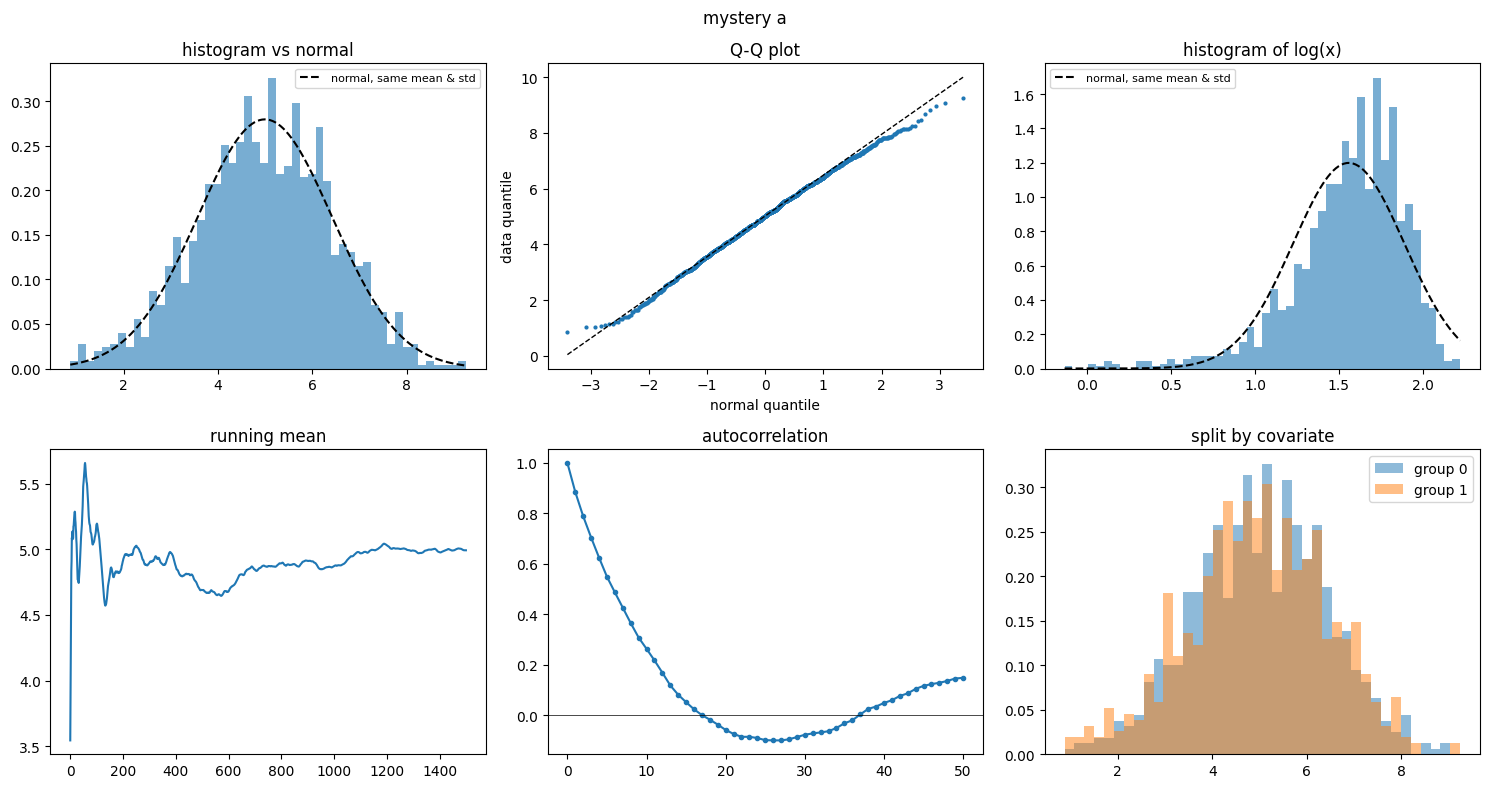

In [26]:
diagnose(mystery["a"], mystery["a_group"], "mystery a")

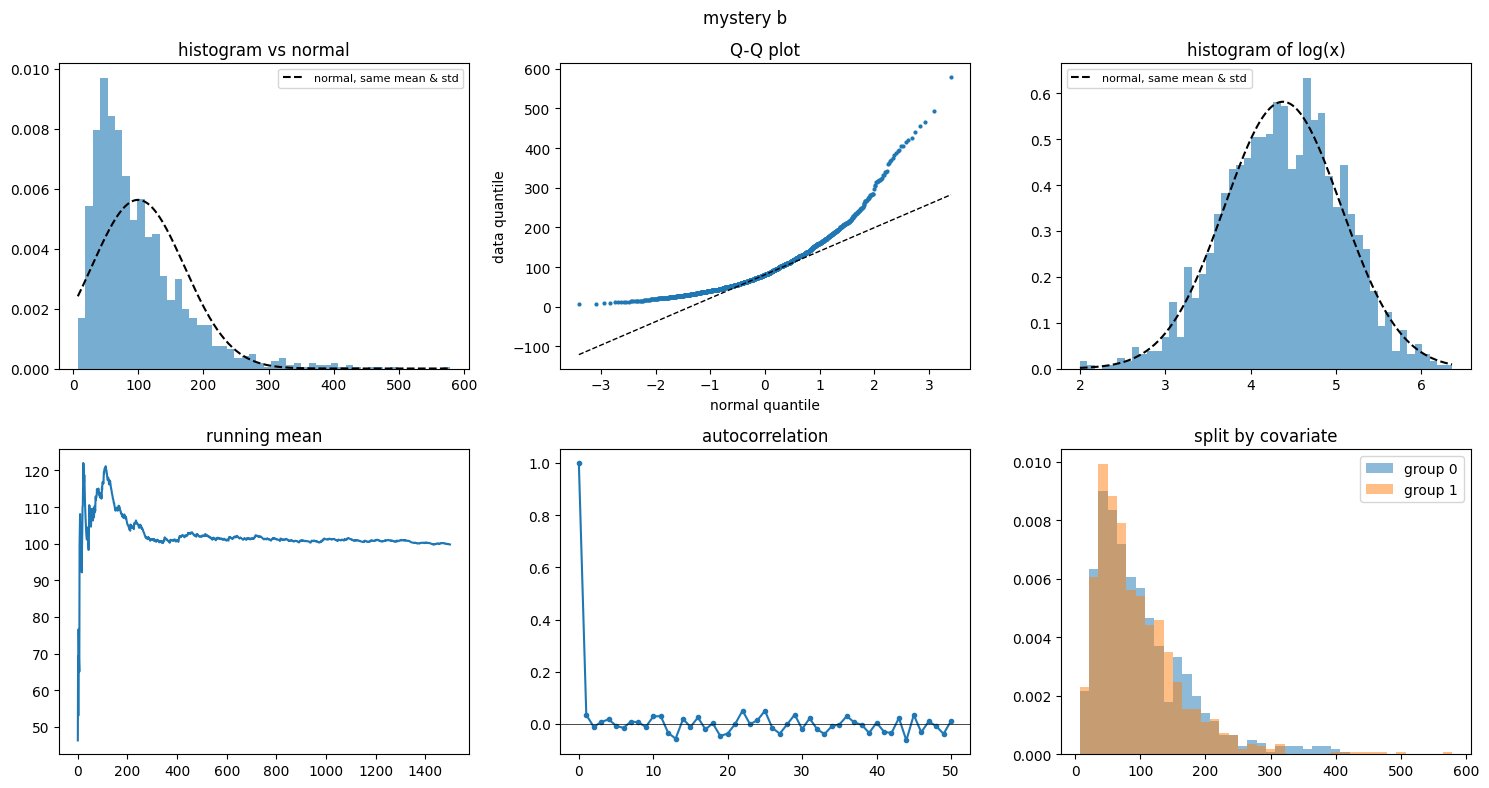

In [27]:
# mystery b
diagnose(mystery["b"], mystery["b_group"], "mystery b")

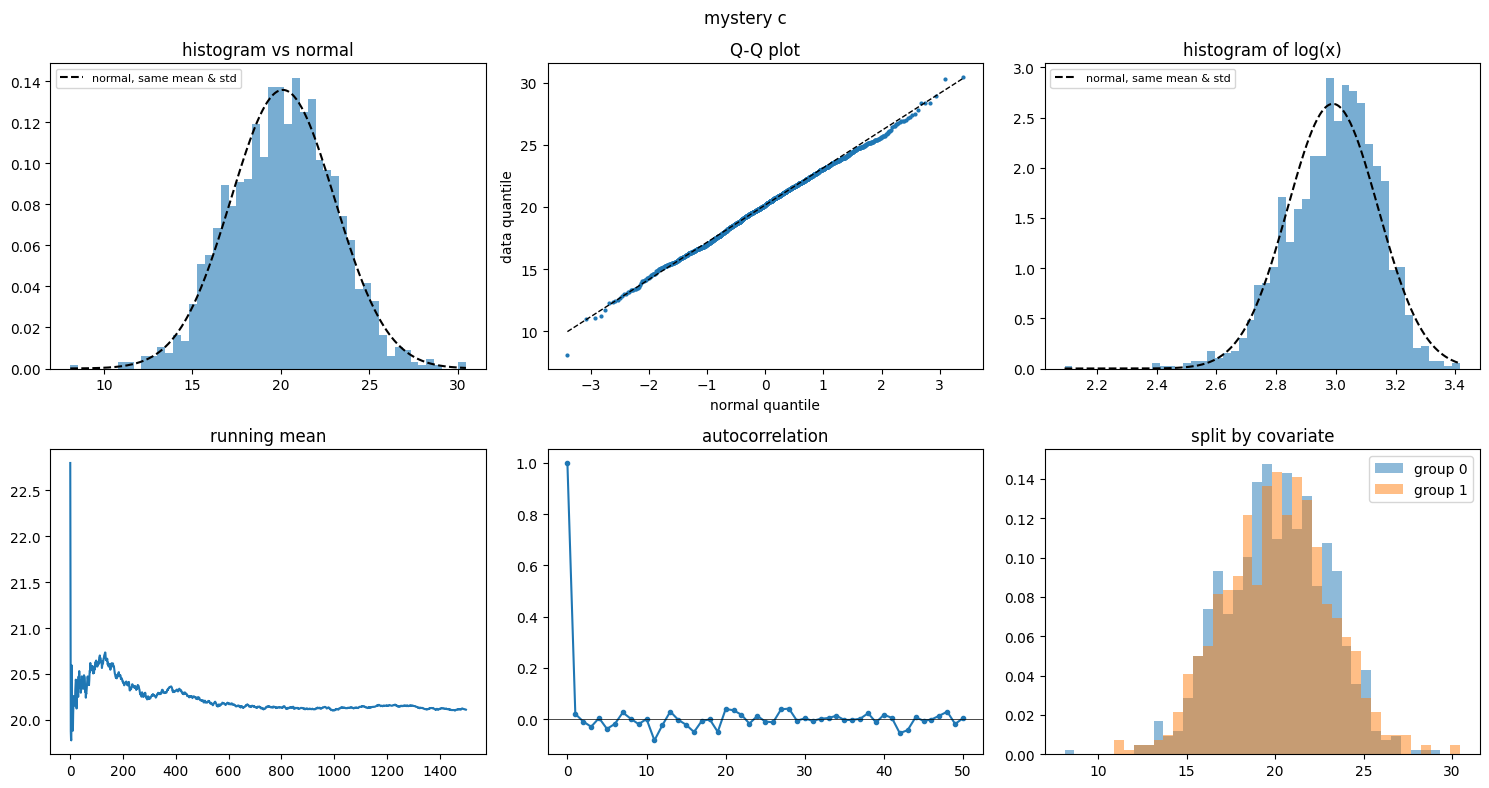

In [28]:
# mystery c
diagnose(mystery["c"], mystery["c_group"], "mystery c")

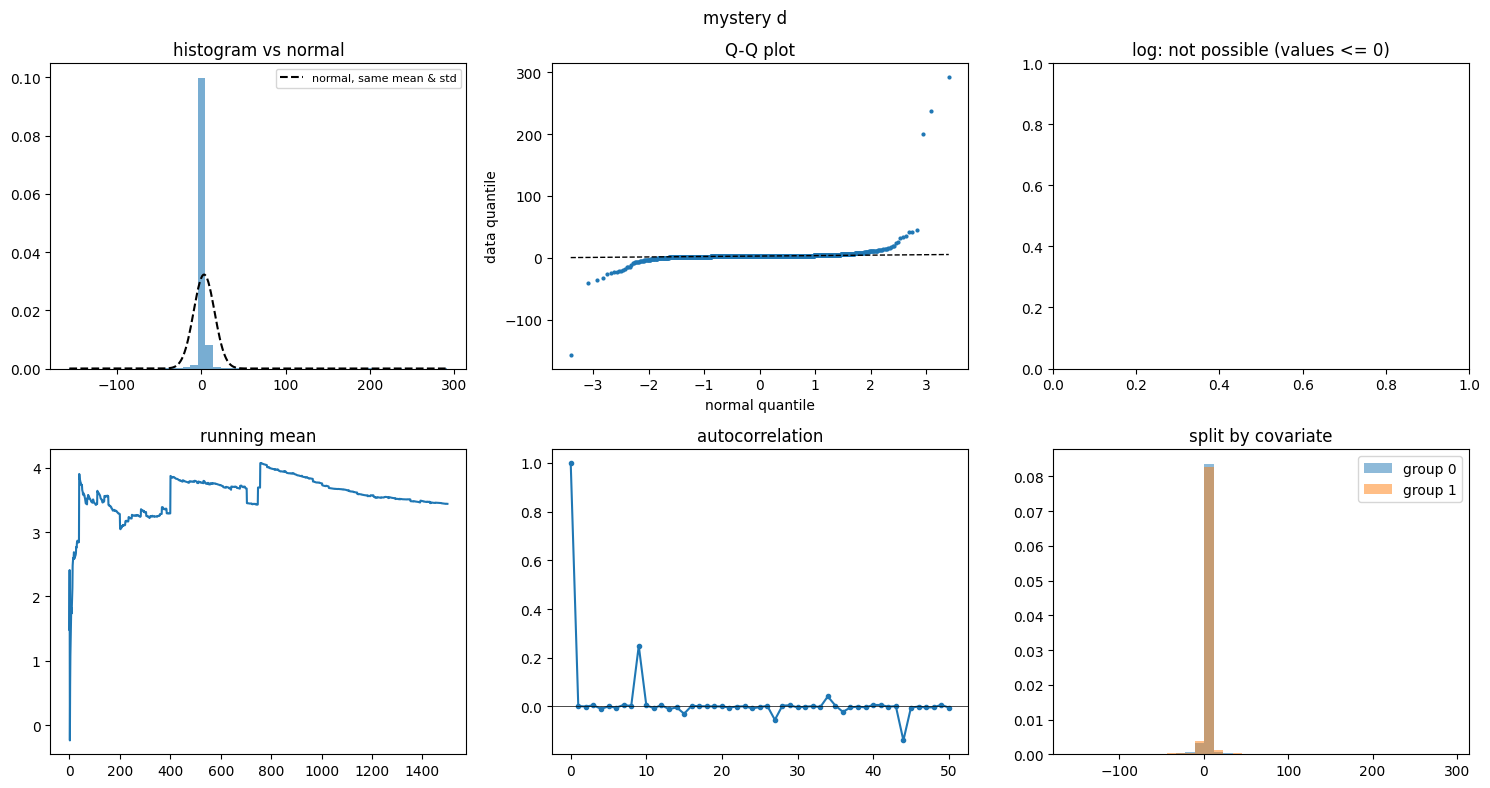

In [29]:
# mystery d
diagnose(mystery["d"], mystery["d_group"], "mystery d")

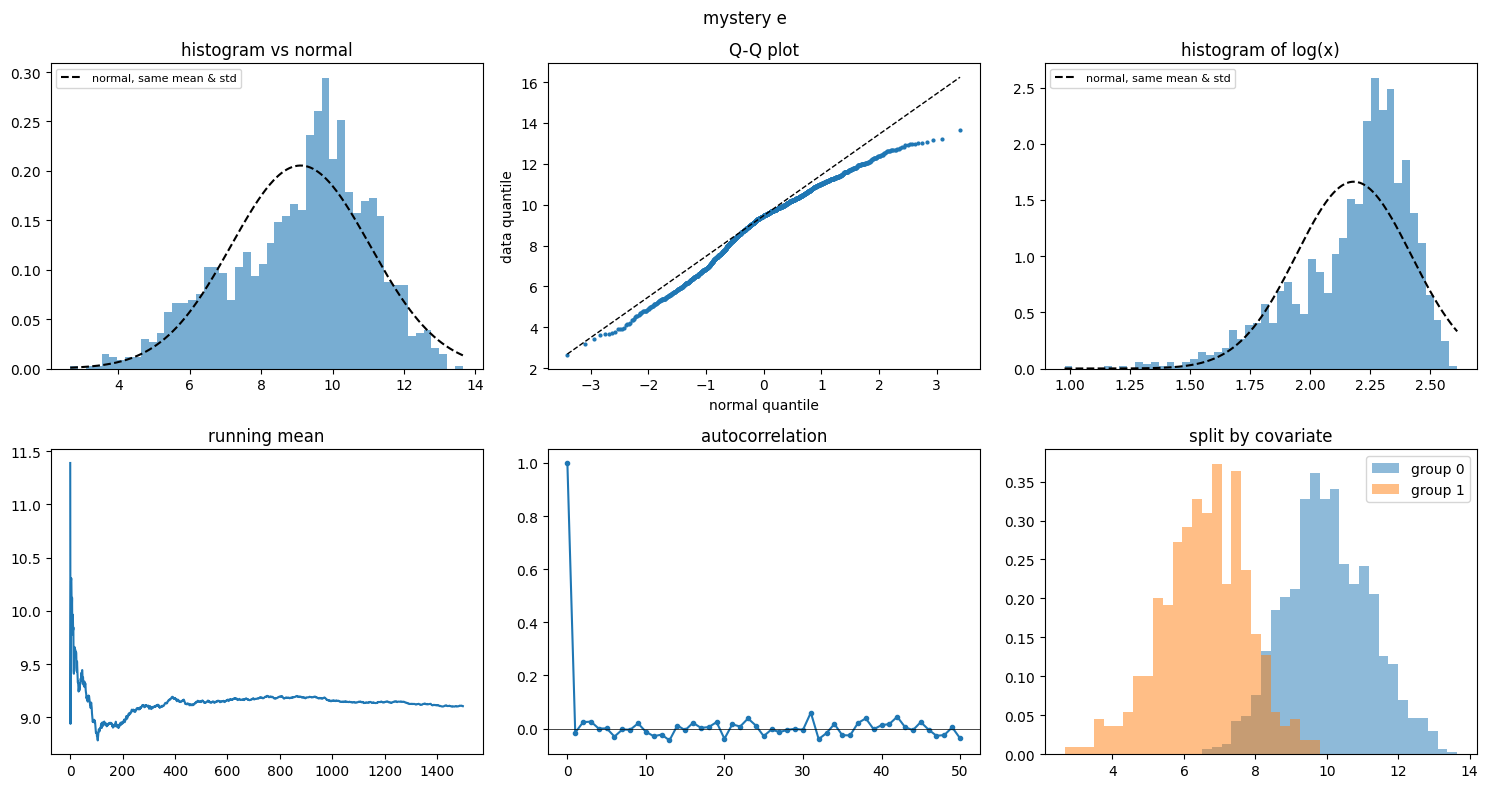

In [30]:
# mystery e
diagnose(mystery["e"], mystery["e_group"], "mystery e")

## What to hand in

Fill in the table, in this notebook. One line of reasoning per dataset is enough — what
matters is that the panel you name is the one that actually shows the problem.

| Dataset | Which assumption broke (or none) | Which panel told you | What you would do next with real data of this kind |
|---|---|---|---|
| `a` | Correlated samples; independence fails | Autocorrelation: strong positive values at short lags that decay slowly, even though the histogram and Q–Q plot look normal | Preserve row order and use a block bootstrap or a model for dependence when estimating uncertainty. |
| `b` | Product process; a normal model on the original scale is unsuitable | Histogram of log(x): much more bell-shaped than the strongly right-skewed original histogram | Analyze log(x), check its diagnostics, and use a multiplicative or lognormal model if appropriate. |
| `c` | None apparent; ordinary normal sample | Histogram and Q–Q plot agree with a normal shape; autocorrelation beyond lag 0 stays near zero and the groups overlap | Keep the original scale and use the mean with an ordinary SE, while checking the sampling design. |
| `d` | Heavy tails; normal-tail assumptions fail | Q–Q plot: both ends depart sharply from the line; the running mean also jumps when extremes occur | Check extreme observations and use a robust summary such as the median for typical location; investigate tail behavior before trusting mean-based inference. |
| `e` | Mixture of two populations; one common normal population is unsuitable | Split by covariate: the two groups have clearly different centers | Analyze the groups separately or include the group covariate in a model, and check within-group distributions. |

Two warnings, from the people who did this before you:

* One of the five passes every test of **shape** — its histogram and its Q–Q plot look
  perfectly normal. If you only look at the top row of panels, you will call it clean.
* Not every non-normal histogram is a broken assumption, and exactly one dataset here is
  fine. Resist diagnosing it anyway.


## Test your diagnosis

Diagnosing a problem is only the first step. Now test whether the action you proposed actually helps. There are three short checks.

**Do not change your original diagnosis table.** These are follow-up checks.


### 1. Test a transformation

Which dataset do you think came from a multiplicative/product process?

Enter its letter below, apply a log transformation, and run the diagnostics again.

Compare the transformed result with the original, especially the **histogram** and **Q-Q plot**.

In 2–3 sentences, answer:

- Did the transformation make the data look more compatible with a normal model?
- What changed?


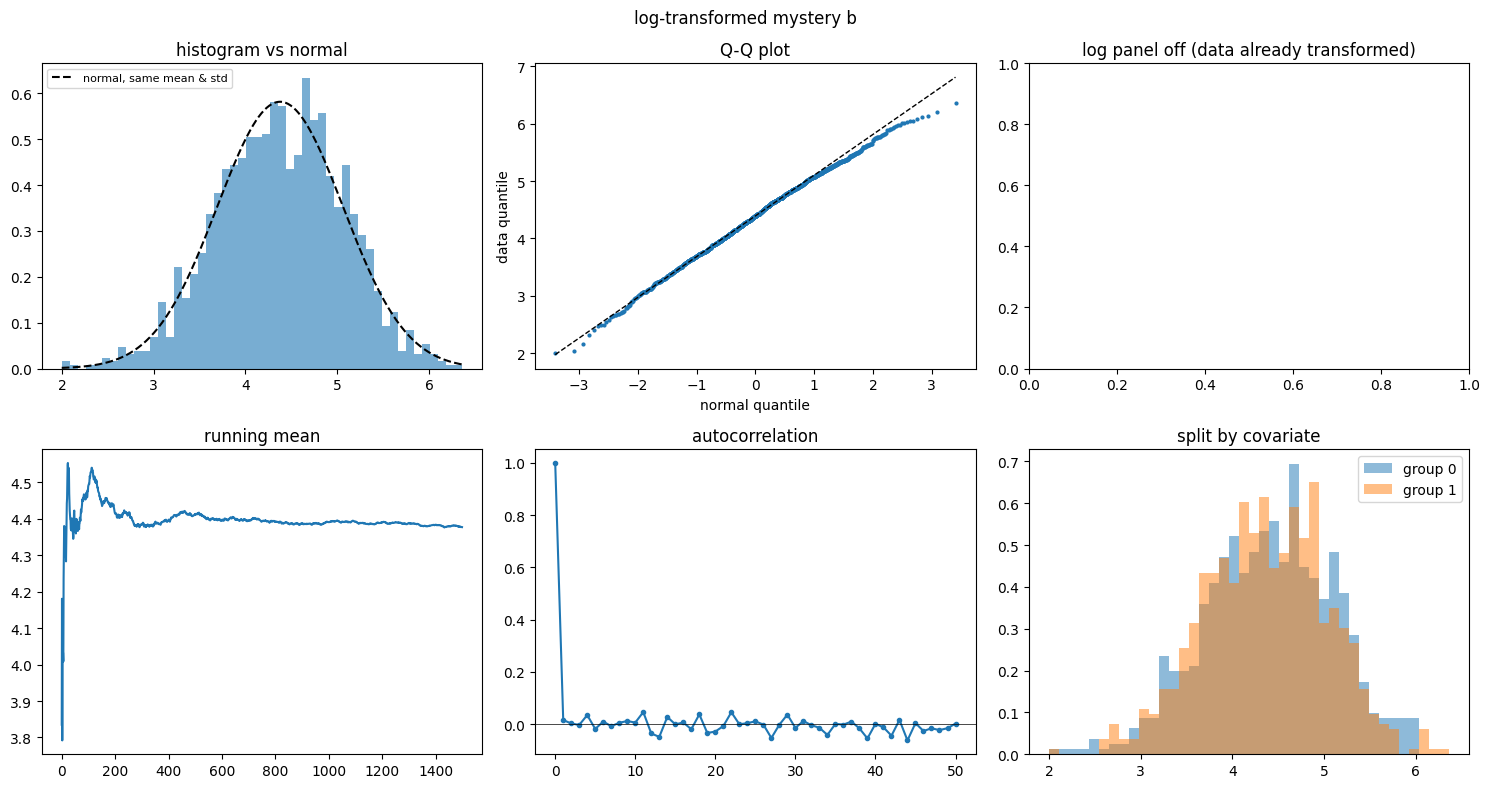

In [31]:
product_name = "b"   # enter a, b, c, d, or e

if product_name not in ["a", "b", "c", "d", "e"]:
    print("Enter one dataset letter: a, b, c, d, or e.")
else:
    x = mystery[product_name]
    g = mystery[product_name + "_group"]

    if np.all(x > 0):
        x_log = np.log(x)
        diagnose(
            x_log,
            g,
            "log-transformed mystery " + product_name,
            log_panel=False
        )
    else:
        print(
            "This dataset contains non-positive values, so log(x) is not "
            "defined for every observation. Revisit your diagnosis."
        )


**What changed after the transformation?**

Yes, logging dataset b makes it look more compatible with a normal model. The long right tail becomes much less pronounced, the histogram becomes roughly symmetric, and the Q–Q points lie much closer to a straight line, with some remaining tail deviations.


### 2. Test the possible mixture

Which dataset do you think contains a mixture of two populations?

Choose that dataset below and examine **group 0** and **group 1** separately.

Compare:

- their means and standard deviations,
- their distributions,
- whether each group looks simpler than the combined sample.

**Note:** the running-mean and autocorrelation panels are not meaningful on a single group, because dropping rows breaks the row order. Look at the histogram and Q-Q plot here.


In [32]:
mixture_name = "e"   # enter a, b, c, d, or e

if mixture_name not in ["a", "b", "c", "d", "e"]:
    print("Enter one dataset letter: a, b, c, d, or e.")
else:
    x = mystery[mixture_name]
    g = mystery[mixture_name + "_group"]

    x0 = x[g == 0]
    x1 = x[g == 1]

    print(
        "group 0:",
        "n =", len(x0),
        "mean =", np.mean(x0),
        "std =", np.std(x0)
    )

    print(
        "group 1:",
        "n =", len(x1),
        "mean =", np.mean(x1),
        "std =", np.std(x1)
    )


group 0: n = 1100 mean = 10.023609483068928 std = 1.2076160077192382
group 1: n = 400 mean = 6.5783802616725096 std = 1.1958270534509683


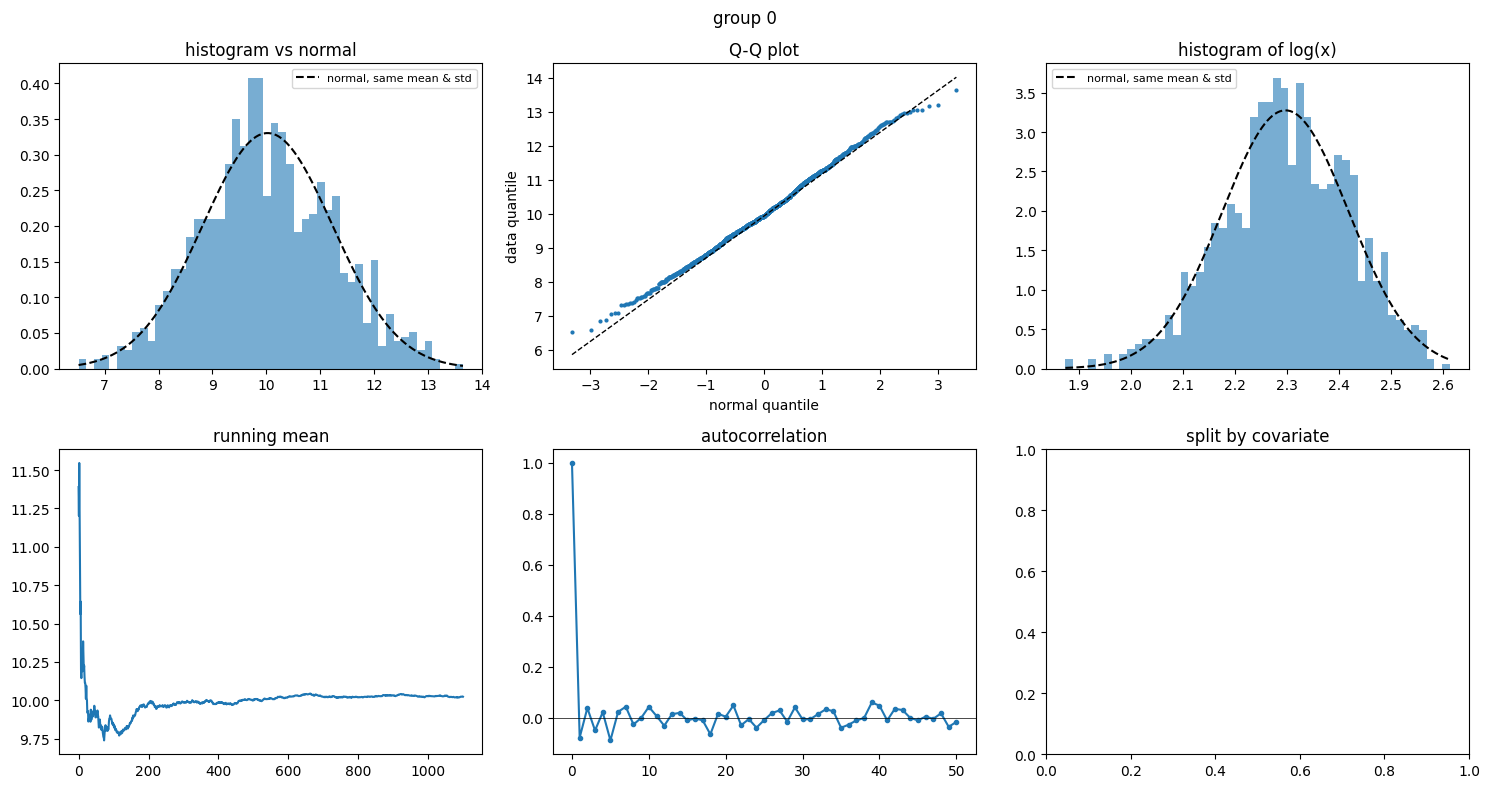

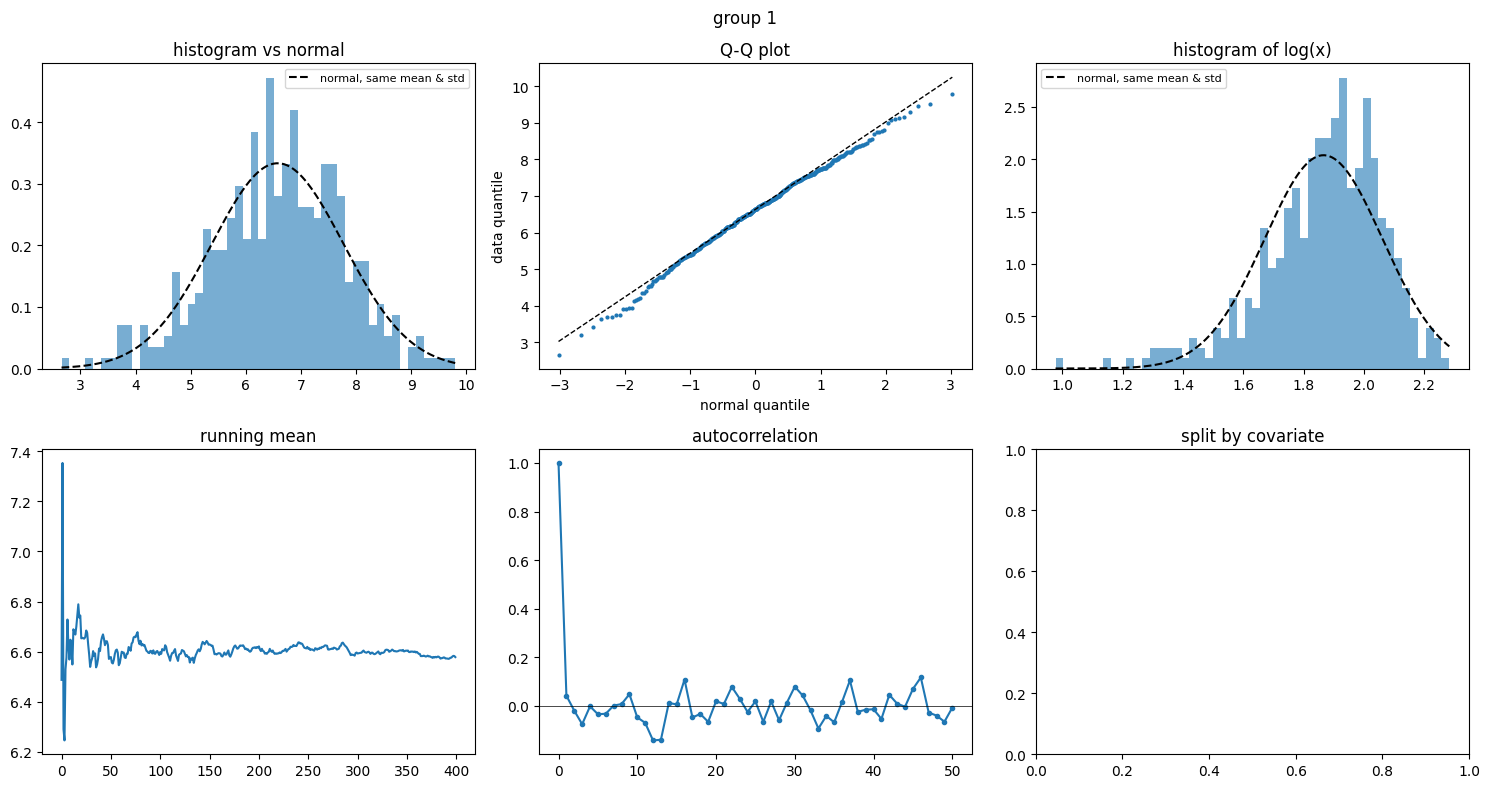

In [33]:
if mixture_name in ["a", "b", "c", "d", "e"]:
    diagnose(x0, name="group 0")
    diagnose(x1, name="group 1")


**After separating the groups, does your mixture diagnosis look more convincing? Why?**

Yes, the mixture diagnosis is more convincing after separating dataset e by group. Group 0 has a mean of about 10.024 and a standard deviation of 1.208, while group 1 has a mean of about 6.578 and a standard deviation of 1.196. Each group looks approximately bell-shaped with a much straighter Q–Q plot, so combining two different centers explains the irregular shape of the full sample.


### 3. Diagnosis vs. treatment

Naming a problem is not the same as fixing it. For two of the datasets, test whether the treatment you would choose actually changes the answer.

We care about one number: the **mean** of the dataset, and how precisely we know it. The **standard error (SE)** is the uncertainty on that number — smaller means more precise. The helper below estimates an SE by bootstrap: resample the data many times, recompute the statistic each time, and take the spread.

* `block=1` resamples single rows (fine when rows are independent).
* `block=50` resamples chunks of 50 consecutive rows, so neighbouring rows stay together and any dependence between them is kept.

In [34]:
def bootstrap_se(x, stat=np.mean, block=1, n_boot=2000, seed=0):
    """Bootstrap standard error of stat(x). block > 1 resamples chunks of consecutive rows."""
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    n = len(x)
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n_blocks, (n_boot, n_blocks)) * block
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]
    samples = x[np.minimum(idx, n - 1)]
    return np.std(stat(samples, axis=1))

**3a. The correlated dataset.** Enter its letter. Compare the naive SE (which assumes independent rows) with the block-bootstrap SE (which does not).

In [35]:
corr_name = "a"   # enter a, b, c, d, or e

if corr_name not in ["a", "b", "c", "d", "e"]:
    print("Enter one dataset letter: a, b, c, d, or e.")
else:
    x = mystery[corr_name]
    print("mean:                          ", np.mean(x))
    print("naive SE (assumes independent):", np.std(x, ddof=1) / np.sqrt(len(x)))
    print("block-bootstrap SE (block=50): ", bootstrap_se(x, np.mean, block=50))

mean:                           4.992392627391782
naive SE (assumes independent): 0.03684092171356295
block-bootstrap SE (block=50):  0.11576018347718767


**Your answer (2 sentences):** Which SE would you report, and what does the gap between the two tell you about how much data you really have?

I would report the block-bootstrap SE of about 0.1158 rather than the naive SE of 0.03684 because neighboring observations in dataset a are correlated. The larger SE shows that the 1,500 rows contain less independent information than 1,500 independent observations, so the naive estimate overstates precision.


**3b. The heavy-tailed dataset.** Enter its letter. Compare the mean with the median, and how precisely each one is estimated.

In [36]:
tail_name = "d"   # enter a, b, c, d, or e

if tail_name not in ["a", "b", "c", "d", "e"]:
    print("Enter one dataset letter: a, b, c, d, or e.")
else:
    x = mystery[tail_name]
    print("mean:   ", np.mean(x),   "  SE of mean:  ", bootstrap_se(x, np.mean))
    print("median: ", np.median(x), "  SE of median:", bootstrap_se(x, np.median))
    print("largest |value|:", np.max(np.abs(x)), "  typical spread (IQR):", np.subtract(*np.percentile(x, [75, 25])))

mean:    3.43844668155372   SE of mean:   0.3220438807205929
median:  3.0071175982514977   SE of median: 0.025847962673370552
largest |value|: 291.8860760749299   typical spread (IQR): 0.9803251839983336


**Your answer (2 sentences):** Which summary would you report, and why? What would you also do about the extreme observations before trusting either number?

For typical location, I would report the median of about 3.007 (bootstrap SE 0.02585), since the mean of about 3.438 (bootstrap SE 0.3220) is much more sensitive to the extreme observations; the median does not replace the mean if the arithmetic mean is the actual target. Before trusting either number, I would check the extreme observations for recording or measurement errors and investigate whether they are genuine, keeping valid extremes rather than deleting them just because they are large.


**3c. Reflection (2–3 sentences).** One of the five datasets needed no treatment at all. Which one, and what could go wrong if you "treated" it anyway (for example by logging it or switching to the median)?

Dataset c needed no treatment: its original histogram and Q–Q plot look approximately normal, its running mean settles, and there is no clear serial dependence or group separation. Logging it would change the scale and introduce unnecessary asymmetry, while switching to the median would generally lose precision for the center of a normal population.
